In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("finance_economics_dataset.csv")

In [4]:
df

,Date,Stock Index,Open Price,Close Price,Daily High,Daily Low,Trading Volume,GDP Growth (%),Inflation Rate (%),Unemployment Rate (%),...,Forex USD/EUR,Forex USD/JPY,Crude Oil Price (USD per Barrel),Gold Price (USD per Ounce),Real Estate Index,Retail Sales (Billion USD),Bankruptcy Rate (%),Mergers & Acquisitions Deals,Venture Capital Funding (Billion USD),Consumer Spending (Billion USD)
0,2000-01-01,Dow Jones,2128.75,2138.48,2143.70,2100.55,2670411,-0.37,6.06,6.10,...,1.04,119.87,47.20,1052.34,390.23,2229,2.12,3,76.64,4589
1,2000-01-02,S&P 500,2046.82,2036.18,2082.83,2009.53,690220415,3.19,4.95,6.62,...,1.00,98.22,52.84,1957.73,346.23,4156,1.40,21,5.67,10101
2,2000-01-03,Dow Jones,1987.92,1985.26,2022.28,1978.37,315284661,5.54,9.13,2.60,...,0.83,80.13,78.80,2339.49,439.46,340,0.79,48,39.43,13665
3,2000-01-04,Dow Jones,4625.02,4660.47,4665.26,4595.46,13098297,10.00,3.77,2.20,...,0.95,149.15,28.18,1308.54,213.07,8456,4.22,16,12.83,5192
4,2000-01-05,S&P 500,1998.18,1982.18,2044.31,1966.44,385306746,1.53,2.20,8.20,...,1.43,113.71,92.20,2210.08,405.49,1596,2.21,34,86.37,10688
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2995,2008-03-14,Dow Jones,1273.76,1235.44,1317.28,1192.34,86910001,8.84,7.00,10.44,...,1.18,113.52,61.98,2385.41,298.72,3033,8.75,35,66.01,2200
2996,2008-03-15,S&P 500,4589.59,4566.91,4607.56,4545.69,303579301,-1.88,9.15,5.61,...,1.17,147.10,31.61,2147.13,143.43,7950,5.07,18,25.49,5261
2997,2008-03-16,S&P 500,1477.52,1448.47,1523.86,1402.69,442387176,4.07,0.88,8.91,...,1.02,81.99,45.64,1943.61,105.81,3894,5.78,4,14.29,12039
2998,2008-03-17,NASDAQ,2311.37,2306.90,2346.30,2282.00,523425925,1.06,8.61,10.15,...,1.49,86.42,123.25,2211.40,236.07,2543,2.35,22,94.34,11979


In [5]:
print("Shape of dataset:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Shape of dataset: (3000, 24)

Column names:
['Date', 'Stock Index', 'Open Price', 'Close Price', 'Daily High', 'Daily Low', 'Trading Volume', 'GDP Growth (%)', 'Inflation Rate (%)', 'Unemployment Rate (%)', 'Interest Rate (%)', 'Consumer Confidence Index', 'Government Debt (Billion USD)', 'Corporate Profits (Billion USD)', 'Forex USD/EUR', 'Forex USD/JPY', 'Crude Oil Price (USD per Barrel)', 'Gold Price (USD per Ounce)', 'Real Estate Index', 'Retail Sales (Billion USD)', 'Bankruptcy Rate (%)', 'Mergers & Acquisitions Deals', 'Venture Capital Funding (Billion USD)', 'Consumer Spending (Billion USD)']


In [6]:
print("\nFirst 5 rows:")
print(df.head())


First 5 rows:
         Date Stock Index  Open Price  Close Price  Daily High  Daily Low  \
0  2000-01-01   Dow Jones     2128.75      2138.48     2143.70    2100.55   
1  2000-01-02     S&P 500     2046.82      2036.18     2082.83    2009.53   
2  2000-01-03   Dow Jones     1987.92      1985.26     2022.28    1978.37   
3  2000-01-04   Dow Jones     4625.02      4660.47     4665.26    4595.46   
4  2000-01-05     S&P 500     1998.18      1982.18     2044.31    1966.44   

   Trading Volume  GDP Growth (%)  Inflation Rate (%)  Unemployment Rate (%)  \
0         2670411           -0.37                6.06                   6.10   
1       690220415            3.19                4.95                   6.62   
2       315284661            5.54                9.13                   2.60   
3        13098297           10.00                3.77                   2.20   
4       385306746            1.53                2.20                   8.20   

   ...  Forex USD/EUR  Forex USD/JPY  Cru

In [7]:
print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 24 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Date                                   3000 non-null   object 
 1   Stock Index                            3000 non-null   object 
 2   Open Price                             3000 non-null   float64
 3   Close Price                            3000 non-null   float64
 4   Daily High                             3000 non-null   float64
 5   Daily Low                              3000 non-null   float64
 6   Trading Volume                         3000 non-null   int64  
 7   GDP Growth (%)                         3000 non-null   float64
 8   Inflation Rate (%)                     3000 non-null   float64
 9   Unemployment Rate (%)                  3000 non-null   float64
 10  Interest Rate (%)                      3000 non-nu

In [8]:
# Convert Date column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numeric values with median
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Date                                     0
Stock Index                              0
Open Price                               0
Close Price                              0
Daily High                               0
Daily Low                                0
Trading Volume                           0
GDP Growth (%)                           0
Inflation Rate (%)                       0
Unemployment Rate (%)                    0
Interest Rate (%)                        0
Consumer Confidence Index                0
Government Debt (Billion USD)            0
Corporate Profits (Billion USD)          0
Forex USD/EUR                            0
Forex USD/JPY                            0
Crude Oil Price (USD per Barrel)         0
Gold Price (USD per Ounce)               0
Real Estate Index                        0
Retail Sales (Billion USD)               0
Bankruptcy Rate (%)                      0
Mergers & Acquisitions Deals             0
Venture Capital Funding

In [9]:
# Daily price change
df["Daily Price Delta"] = df["Close Price"] - df["Open Price"]

# Daily percentage return
df["Daily Return (%)"] = (
    (df["Close Price"] - df["Open Price"])
    / df["Open Price"]
) * 100

# Daily trading range
df["Trading Range"] = df["Daily High"] - df["Daily Low"]

# Profit/Loss indicator
df["Market Movement"] = np.where(
    df["Daily Price Delta"] > 0,
    "Profit",
    np.where(df["Daily Price Delta"] < 0, "Loss", "No Change")
)

print(df[[
    "Date",
    "Stock Index",
    "Open Price",
    "Close Price",
    "Daily Price Delta",
    "Daily Return (%)",
    "Trading Range",
    "Market Movement"
]].head())

        Date Stock Index  Open Price  Close Price  Daily Price Delta  \
0 2000-01-01   Dow Jones     2128.75      2138.48               9.73   
1 2000-01-02     S&P 500     2046.82      2036.18             -10.64   
2 2000-01-03   Dow Jones     1987.92      1985.26              -2.66   
3 2000-01-04   Dow Jones     4625.02      4660.47              35.45   
4 2000-01-05     S&P 500     1998.18      1982.18             -16.00   

   Daily Return (%)  Trading Range Market Movement  
0          0.457076          43.15          Profit  
1         -0.519831          73.30            Loss  
2         -0.133808          43.91            Loss  
3          0.766483          69.80          Profit  
4         -0.800729          77.87            Loss  


In [10]:
stock_summary = df.groupby("Stock Index").agg({
    "Open Price": "mean",
    "Close Price": "mean",
    "Daily Price Delta": "mean",
    "Daily Return (%)": "mean",
    "Trading Volume": "mean"
}).round(2)

print("\nStock Index Summary:")
print(stock_summary)


Stock Index Summary:
             Open Price  Close Price  Daily Price Delta  Daily Return (%)  \
Stock Index                                                                 
Dow Jones       3004.94      3004.46              -0.49             -0.04   
NASDAQ          2987.02      2985.91              -1.11             -0.02   
S&P 500         2956.21      2955.29              -0.92             -0.03   

             Trading Volume  
Stock Index                  
Dow Jones      4.991151e+08  
NASDAQ         4.959921e+08  
S&P 500        5.145193e+08  


In [11]:
economic_summary = df.groupby("Stock Index").agg({
    "GDP Growth (%)": "mean",
    "Inflation Rate (%)": "mean",
    "Unemployment Rate (%)": "mean",
    "Interest Rate (%)": "mean",
    "Consumer Confidence Index": "mean"
}).round(2)

print("\nEconomic Indicators Summary:")
print(economic_summary)


Economic Indicators Summary:
             GDP Growth (%)  Inflation Rate (%)  Unemployment Rate (%)  \
Stock Index                                                              
Dow Jones              2.71                5.19                   8.52   
NASDAQ                 2.62                4.89                   8.87   
S&P 500                2.50                5.21                   8.59   

             Interest Rate (%)  Consumer Confidence Index  
Stock Index                                                
Dow Jones                 5.24                      85.11  
NASDAQ                    5.21                      85.58  
S&P 500                   5.21                      84.44  


In [12]:
business_summary = df.groupby("Stock Index").agg({
    "Corporate Profits (Billion USD)": "mean",
    "Retail Sales (Billion USD)": "mean",
    "Bankruptcy Rate (%)": "mean",
    "Mergers & Acquisitions Deals": "mean",
    "Venture Capital Funding (Billion USD)": "mean",
    "Consumer Spending (Billion USD)": "mean"
}).round(2)

print("\nBusiness Indicators Summary:")
print(business_summary)


Business Indicators Summary:
             Corporate Profits (Billion USD)  Retail Sales (Billion USD)  \
Stock Index                                                                
Dow Jones                            2550.10                     5192.07   
NASDAQ                               2553.23                     5071.48   
S&P 500                              2557.64                     5041.36   

             Bankruptcy Rate (%)  Mergers & Acquisitions Deals  \
Stock Index                                                      
Dow Jones                   5.08                         24.70   
NASDAQ                      5.11                         24.35   
S&P 500                     4.84                         24.75   

             Venture Capital Funding (Billion USD)  \
Stock Index                                          
Dow Jones                                    49.74   
NASDAQ                                       50.04   
S&P 500                                   

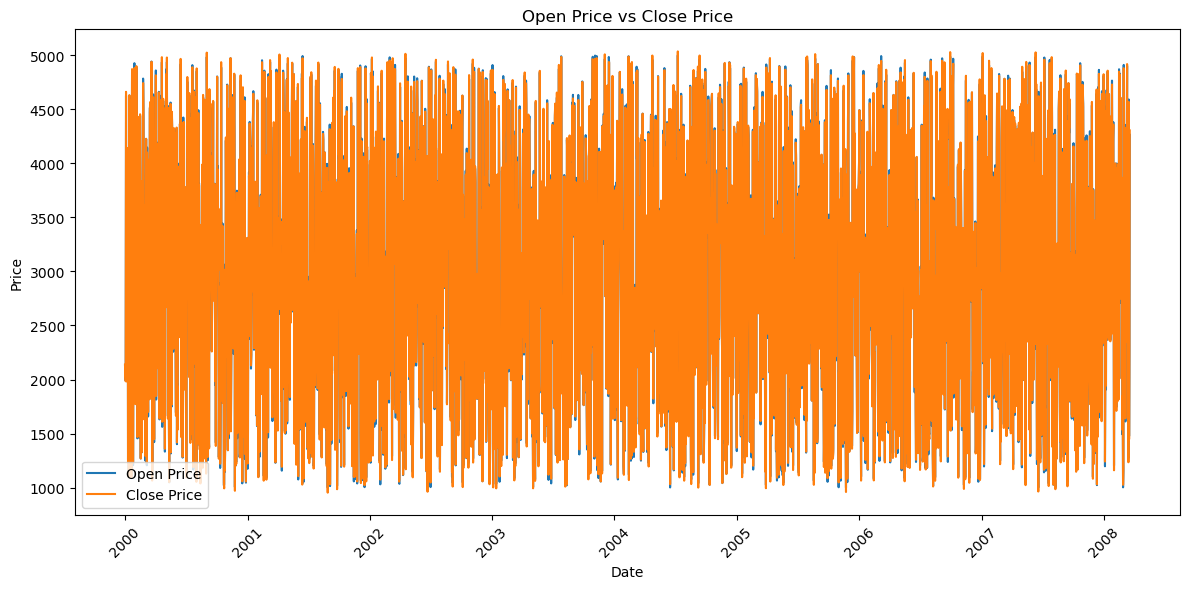

In [13]:
plt.figure(figsize=(12, 6))

plt.plot(df["Date"], df["Open Price"], label="Open Price")
plt.plot(df["Date"], df["Close Price"], label="Close Price")

plt.title("Open Price vs Close Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

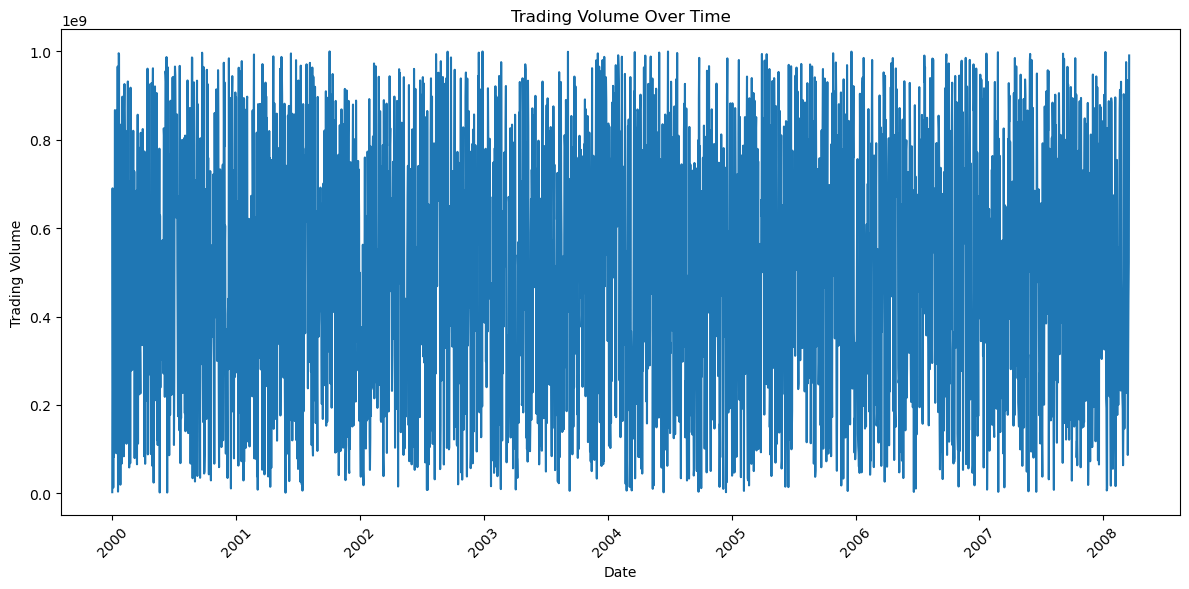

In [14]:
plt.figure(figsize=(12, 6))

plt.plot(df["Date"], df["Trading Volume"])

plt.title("Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Trading Volume")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

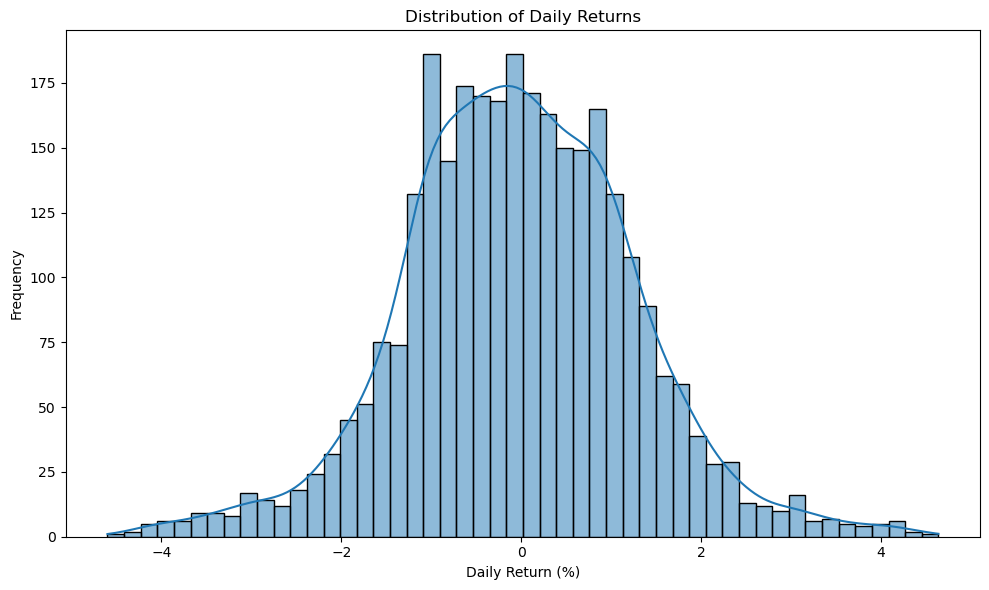

In [15]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["Daily Return (%)"],
    bins=50,
    kde=True
)

plt.title("Distribution of Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

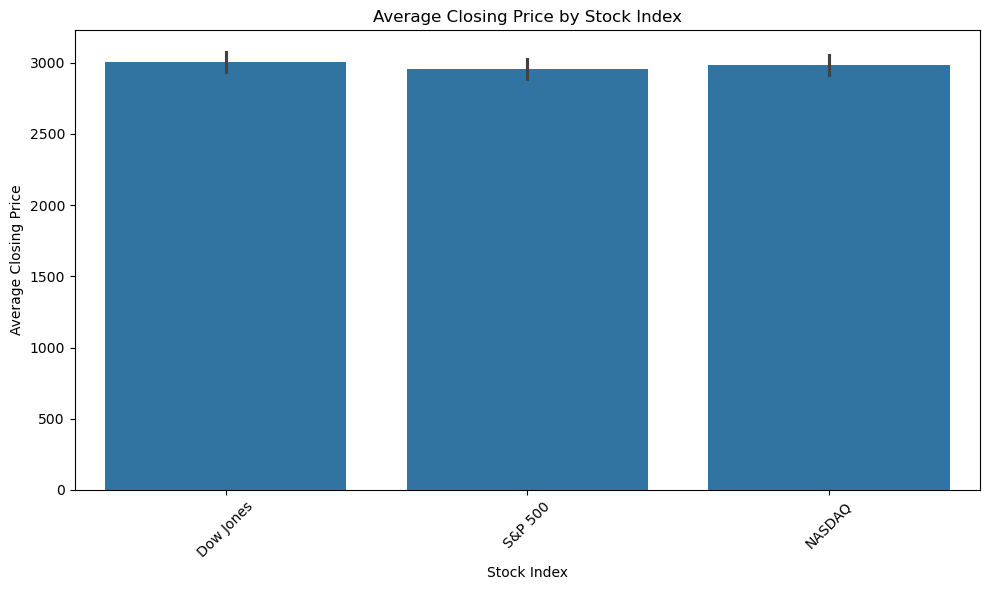

In [16]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Stock Index",
    y="Close Price"
)

plt.title("Average Closing Price by Stock Index")
plt.xlabel("Stock Index")
plt.ylabel("Average Closing Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()